# Do the intervals cover at their stated level with this many matches?

**The question, given the analyses.** Every season contrast in this project comes with a 95% interval built from about 70 match clusters per season, and every team-level rate from about 14. A 95% interval should contain the true value 95% of the time, but whether a cluster bootstrap actually achieves that at these counts is not something theory settles. This notebook checks it by simulation, so the intervals elsewhere can be quoted at their nominal level, or labelled approximate.

**What this notebook does.** It takes real per-cluster (numerator, denominator) pairs for the powerplay run rate and the powerplay six rate, builds artificial seasons by drawing pairs at random from the pooled two-season set, plants a known effect in the later season (or none), runs the exact interval machinery the analyses use, and counts how often the interval covers the planted truth. Twelve scenarios: two rates, differences and a ratio, the league count (70 clusters) and the team count (14), null and non-null effects.

**How to read this notebook.** *Coverage* is the share of simulated datasets whose interval contained the true value; 0.95 is the target. *Bootstrap-t* and *BCa* are the two interval constructions the analyses report; the *percentile* interval is a plain reference. The Monte Carlo standard error is the precision of a coverage estimate from this many datasets (0.002 at 10,000). Mean interval width is shown because a wide interval covers cheaply.

**Numbers in the text.** Quoted from the run of 9 September 2026 under the seed in `config.toml`. Settings come from `config.toml` under `[interval_coverage]`; at the configured 10,000 datasets and 10,000 resamples the twelve scenarios take about half an hour on several cores. Code lives in `scripts/interval_coverage/`.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("scripts").resolve()))

from common.config import load_settings
from common import results_io
from mean_level_and_tail import season_contrast_bootstrap as scb
from interval_coverage import coverage_simulation as cs

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

settings = load_settings()
ANALYSIS = "interval_coverage"
SEED = settings.seed(ANALYSIS)
CFG = settings.section("interval_coverage")
N_DATASETS = int(CFG["n_datasets"])
N_RESAMPLES = int(CFG["n_resamples_per_dataset"])
PRODUCER = "interval_coverage.ipynb"
print(f"root={settings.root}  seed={SEED}  datasets={N_DATASETS}  resamples/dataset={N_RESAMPLES}  n_jobs={CFG['n_jobs']}")

root=/Users/madkad/dpl_2026_s1  seed=202609081209  datasets=10000  resamples/dataset=10000  n_jobs=4


## Data

The real frame supplies the per-cluster pairs. The fixture stands in if it is absent; coverage numbers from it still describe the interval methods, but at the fixture's rates and cluster sizes rather than the real ones.

In [2]:
DATA_PATH = settings.data_path("cleaned_dataset")
USING_FIXTURE = not DATA_PATH.exists()
if USING_FIXTURE:
    from common.synthetic_ballframe import make_synthetic_ballframe
    df = make_synthetic_ballframe(seed=7)
    print("REAL DATA ABSENT: running on the synthetic fixture")
else:
    df = scb.load_cleaned_dataset(str(DATA_PATH))
print(f"rows={len(df):,}  matches={df['p_match'].nunique()}")

rows=34,967  matches=145


## The pools the simulation draws from

Size and pooled rate of each pool. The team-innings pool has about twice the match pool's size (two batting innings per match) and half the denominator per cluster, which is what makes a team-level rate noisier.

In [3]:
pools = cs.observed_pair_pools(df, settings.phase("powerplay"))
pool_table = pd.DataFrame([{"rate": p.rate, "cluster_kind": p.cluster_kind, "n_clusters_in_pool": len(p.numerator),
                            "pooled_rate": p.rate_value * (6.0 if cs.RATES[p.rate]["per_over"] else 1.0),
                            "median_denominator": float(np.median(p.denominator))} for p in pools.values()])
results_io.write_table(pool_table, settings, ANALYSIS, "cluster_pair_pools", SEED, PRODUCER, {"fixture": USING_FIXTURE})
pool_table

,rate,cluster_kind,n_clusters_in_pool,pooled_rate,median_denominator
0,powerplay_run_rate,match,145,8.729527,72.0
1,powerplay_run_rate,team_innings,289,8.729527,36.0
2,powerplay_six_rate,match,145,0.055083,72.0
3,powerplay_six_rate,team_innings,289,0.055083,36.0


## Scenarios and coverage

One row per scenario. `coverage_boot_t` and `coverage_bca` are the two primary methods; `coverage_percentile` the reference; `approximate_flag` is set when either primary method covers below 0.90.

In [4]:
scenarios = cs.default_scenarios(CFG)
display(pd.DataFrame(scenarios))
coverage = cs.coverage_table(df, settings, SEED, n_datasets=N_DATASETS, n_resamples=N_RESAMPLES,
                             n_jobs=int(CFG["n_jobs"]), scenarios=scenarios)
results_io.write_table(coverage, settings, ANALYSIS, "interval_coverage", SEED, PRODUCER,
                       {"fixture": USING_FIXTURE, "interval_coverage": CFG,
                        "n_datasets": N_DATASETS, "n_resamples_per_dataset": N_RESAMPLES})
coverage[["rate", "estimand", "cluster_kind", "n_clusters", "effect", "coverage_boot_t", "coverage_bca",
          "coverage_percentile", "mean_width_boot_t", "mean_width_bca", "boot_t_defined_share",
          "monte_carlo_se", "approximate_flag"]].round(4)

,rate,estimand,cluster_kind,n_clusters,effect
0,powerplay_run_rate,difference,match,70,0.00
1,powerplay_run_rate,difference,team_innings,14,0.00
2,powerplay_run_rate,difference,match,70,0.70
3,powerplay_run_rate,difference,team_innings,14,0.70
4,powerplay_six_rate,difference,match,70,0.00
5,powerplay_six_rate,difference,team_innings,14,0.00
6,powerplay_six_rate,difference,match,70,0.01
7,powerplay_six_rate,difference,team_innings,14,0.01
8,powerplay_six_rate,log_ratio,match,70,1.00
9,powerplay_six_rate,log_ratio,team_innings,14,1.00


,rate,estimand,cluster_kind,n_clusters,effect,coverage_boot_t,coverage_bca,coverage_percentile,mean_width_boot_t,mean_width_bca,boot_t_defined_share,monte_carlo_se,approximate_flag
0,powerplay_run_rate,difference,match,70,0.00,0.9442,0.9393,0.9448,1.1733,1.1554,1.0,0.0022,False
1,powerplay_run_rate,difference,team_innings,14,0.00,0.9428,0.9198,0.9295,3.6192,3.2810,1.0,0.0022,False
2,powerplay_run_rate,difference,match,70,0.70,0.9431,0.9379,0.9439,1.1730,1.1551,1.0,0.0022,False
3,powerplay_run_rate,difference,team_innings,14,0.70,0.9413,0.9170,0.9279,3.6277,3.2885,1.0,0.0022,False
4,powerplay_six_rate,difference,match,70,0.00,0.9463,0.9417,0.9459,0.0236,0.0232,1.0,0.0022,False
5,powerplay_six_rate,difference,team_innings,14,0.00,0.9376,0.9125,0.9244,0.0734,0.0663,1.0,0.0022,False
6,powerplay_six_rate,difference,match,70,0.01,0.9443,0.9414,0.9439,0.0236,0.0232,1.0,0.0022,False
7,powerplay_six_rate,difference,team_innings,14,0.01,0.9412,0.9124,0.9238,0.0732,0.0662,1.0,0.0022,False
8,powerplay_six_rate,log_ratio,match,70,1.00,0.9457,0.9424,0.9428,0.4368,0.4286,1.0,0.0022,False
9,powerplay_six_rate,log_ratio,team_innings,14,1.00,0.9347,0.9275,0.9270,1.5274,1.4414,1.0,0.0022,False


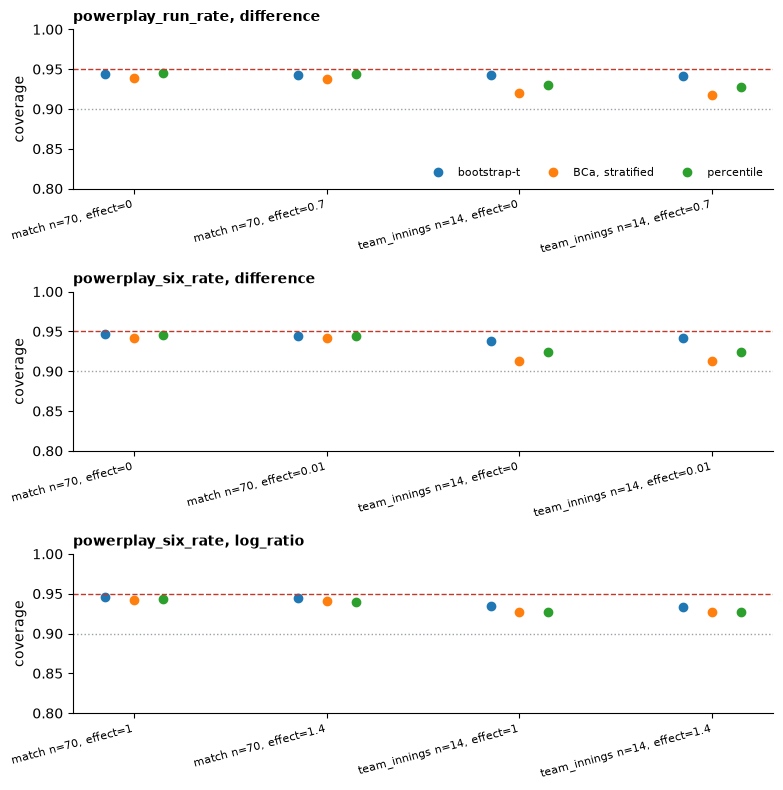

In [5]:
fig = cs.plot_coverage(coverage, settings.interval_level)
results_io.write_figure(fig, settings, ANALYSIS, "interval_coverage", SEED, PRODUCER)
plt.show()

At the league count every method covers about 0.94, within one or two Monte Carlo standard errors of 0.95, for differences and ratios alike, with and without a planted effect: the intervals in the season contrasts are honest at their stated level. At the team count BCa slips to 0.91 to 0.92 while bootstrap-t holds at 0.93 to 0.94; nothing crosses 0.90, so team-level intervals keep the nominal label, but bootstrap-t is the better construction there, which is why it is the primary method for rates throughout. Coverage is the same at zero and at the planted effect, so the intervals do not depend on the size of the effect. Bootstrap-t was defined on every dataset. Its price is width: about 2% wider than BCa at 70 clusters and about 10% wider at 14, which is exactly where BCa's undercoverage comes from. Ratios on the log scale cover as well as differences, supporting that choice.

## The team-level label

Whether any 14-cluster row fell below 0.90 for either primary method.

In [6]:
team_rows = coverage[coverage["cluster_kind"] == "team_innings"]
label = "approximate" if bool(team_rows["approximate_flag"].any()) else "nominal"
print(f"team-level interval label: {label}")
print("lowest team-level coverage, bootstrap-t:", round(float(team_rows["coverage_boot_t"].min()), 4),
      "| BCa:", round(float(team_rows["coverage_bca"].min()), 4))
results_io.write_json({"team_level_interval_label": label,
                       "min_team_coverage_boot_t": float(team_rows["coverage_boot_t"].min()),
                       "min_team_coverage_bca": float(team_rows["coverage_bca"].min())},
                      settings, ANALYSIS, "team_level_interval_label", SEED, PRODUCER, {"fixture": USING_FIXTURE})

team-level interval label: nominal
lowest team-level coverage, bootstrap-t: 0.9332 | BCa: 0.9124


PosixPath('/Users/madkad/dpl_2026_s1/outputs/interval_coverage/team_level_interval_label.json')

No; the lowest team-level coverage is 0.93 for bootstrap-t and 0.91 for BCa, so team-level intervals elsewhere are quoted as nominal.